In [ ]:
# Paths: set DATA_DIR / OUTPUT_DIR as environment variables, or edit the defaults below.
import os
DATA_DIR = os.environ.get("DATA_DIR", "../data")


In [ ]:
!pip install torch torchvision scikit-learn -q

import torch, shutil, random
import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter, defaultdict
pass  # Colab only: from google.colab import drive

pass  # Colab only: drive.mount('/content/drive')

ROOT = Path(DATA_DIR)

WORKING   = ROOT / '00_working'
CROPS     = WORKING / 'crops'
CLEAN_XLS = WORKING / 'annotations_clean.xlsx'

CLS_DIR   = ROOT / '02_classification'
DATA_DIR  = CLS_DIR / 'data'
RUNS      = CLS_DIR / 'runs'
RESULTS   = ROOT / '05_results'

MATERIALS   = ['glass', 'metal', 'pottery', 'misc']
SPLIT_SEED  = 42
SPLIT_RATIO = (0.70, 0.15, 0.15)             # train / valid / test

for d in (DATA_DIR, RUNS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)


print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
print("Crops folder exists:", CROPS.exists(), "| images:",
      len(list(CROPS.glob('*'))) if CROPS.exists() else 0)
print("Clean annotation exists:", CLEAN_XLS.exists())

Mounted at /content/drive
GPU: Tesla T4
Crops folder exists: True | images: 559
Clean annotation exists: True


In [ ]:
df = pd.read_excel(CLEAN_XLS)
df.columns = [str(c).strip() for c in df.columns]
print("Columns:", list(df.columns))

id_to_material = {}
for _, row in df.iterrows():
    inv = str(row['Inv. no.']).strip()
    mat = str(row['Material_4']).strip()
    id_to_material[inv] = mat

crop_files = {p.stem.strip(): p for p in CROPS.iterdir()
              if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}}

matched, unlabelled, no_label = [], [], []
for stem, path in crop_files.items():
    mat = id_to_material.get(stem)
    if mat is None:
        no_label.append(stem)
    elif mat == 'unlabelled':
        unlabelled.append(stem)
    elif mat in MATERIALS:
        matched.append((stem, path, mat))
    else:
        no_label.append(stem)

print(f"\nCrops: {len(crop_files)}")
print(f"  Usable (4-class):     {len(matched)}")
print(f"  Excluded (unlabelled):{len(unlabelled)}")
print(f"  No/unknown label:     {len(no_label)}")

print("\nMaterial distribution (usable crops):")
dist = Counter(m for _, _, m in matched)
for mat in MATERIALS:
    print(f"  {mat:10} {dist[mat]}")
print(f"  {'TOTAL':10} {sum(dist.values())}")

if no_label:
    print(f"\n Crops with no/unknown label: {no_label[:10]}"
          + (" ..." if len(no_label) > 10 else ""))

Columns: ['Inv. no.', 'Object', 'Material', 'Material_4']

Crops: 559
  Usable (4-class):     551
  Excluded (unlabelled):8
  No/unknown label:     0

Material distribution (usable crops):
  glass      332
  metal      37
  pottery    131
  misc       51
  TOTAL      551


In [ ]:
random.seed(SPLIT_SEED)

crops_by_material = defaultdict(list)
for stem, path, material in matched:
    crops_by_material[material].append(path)

train_files = []
val_files   = []
test_files  = []

for material, paths in crops_by_material.items():
    random.shuffle(paths)

    total       = len(paths)
    train_count = round(total * 0.70)
    val_count   = round(total * 0.15)

    train_paths = paths[:train_count]
    val_paths   = paths[train_count : train_count + val_count]
    test_paths  = paths[train_count + val_count :]

    for path in train_paths:
        train_files.append((path, material))
    for path in val_paths:
        val_files.append((path, material))
    for path in test_paths:
        test_files.append((path, material))

for split_name in ['train', 'val', 'test']:
    for material in MATERIALS:
        folder = DATA_DIR / split_name / material
        folder.mkdir(parents=True, exist_ok=True)

for path, material in train_files:
    shutil.copy2(path, DATA_DIR / 'train' / material / path.name)
for path, material in val_files:
    shutil.copy2(path, DATA_DIR / 'val' / material / path.name)
for path, material in test_files:
    shutil.copy2(path, DATA_DIR / 'test' / material / path.name)

print("Split complete")


summary_rows = []
for split_name in ['train', 'val', 'test']:
    row = {'split': split_name}
    for material in MATERIALS:
        folder = DATA_DIR / split_name / material
        row[material] = len(list(folder.glob('*')))
    row['TOTAL'] = sum(row[material] for material in MATERIALS)
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)

totals_row = {'split': 'TOTAL'}
for column in summary.columns:
    if column != 'split':
        totals_row[column] = summary[column].sum()
summary = pd.concat([summary, pd.DataFrame([totals_row])], ignore_index=True)

print("\nImages per material in each split:")
print(summary.to_string(index=False))

Split complete

Images per material in each split:
split  glass  metal  pottery  misc  TOTAL
train    232     26       92    36    386
  val     50      6       20     8     84
 test     50      5       19     7     81
TOTAL    332     37      131    51    551


In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

IMAGE_SIZE = 224
BATCH_SIZE = 32

# ImageNet normalisation values
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

train_dataset = datasets.ImageFolder(DATA_DIR / 'train', transform=image_transform)
val_dataset   = datasets.ImageFolder(DATA_DIR / 'val',   transform=image_transform)
test_dataset  = datasets.ImageFolder(DATA_DIR / 'test',  transform=image_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

class_names = train_dataset.classes
num_classes = len(class_names)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("Classes (in model's index order):", class_names)
print("Number of classes:", num_classes)
print("Training images:  ", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:      ", len(test_dataset))
print("Device:", device)

images, labels = next(iter(train_loader))
print("\nOne batch of images has shape:", tuple(images.shape))
print(" (batch size, colour channels, height, width)")
print("One batch of labels has shape: ", tuple(labels.shape))

Classes (in model's index order): ['glass', 'metal', 'misc', 'pottery']
Number of classes: 4
Training images:   386
Validation images: 84
Test images:       81
Device: cuda

One batch of images has shape: (32, 3, 224, 224)
 (batch size, colour channels, height, width)
One batch of labels has shape:  (32,)


#Dense (feed-forward) network

In [ ]:
import torch.nn as nn

class DenseNetwork(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        input_size = 3 * 224 * 224

        self.flatten = nn.Flatten()

        self.layers = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.layers(x)
        return x


dense_model = DenseNetwork(num_classes).to(device)
print(dense_model)

param_count = sum(p.numel() for p in dense_model.parameters())
print(f"\nTrainable parameters: {param_count:,}")

images, labels = next(iter(train_loader))
images = images.to(device)
output = dense_model(images)
print(f"Output shape for a batch of 32: {tuple(output.shape)}")
print("  -> (batch size, number of classes) - one score per material, per image")

DenseNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=150528, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=512, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.5, inplace=False)
    (6): Linear(in_features=128, out_features=4, bias=True)
  )
)

Trainable parameters: 77,137,028
Output shape for a batch of 32: (32, 4)
  -> (batch size, number of classes) - one score per material, per image


In [ ]:
import torch.optim as optim

train_label_counts = Counter(label for _, label in train_dataset.samples)

class_weights = []
for class_index in range(num_classes):
    count = train_label_counts[class_index]
    weight = len(train_dataset) / (num_classes * count)
    class_weights.append(weight)

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print("Class weights (higher = rarer class, counts more):")
for name, weight in zip(class_names, class_weights):
    print(f"  {name:10} {weight:.2f}")


def train_model(model, model_name, epochs=30, learning_rate=0.001):
    loss_function = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    best_val_accuracy = 0.0
    best_model_state = None

    for epoch in range(epochs):
        # training pass
        model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()

        # validation pass
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                predictions = outputs.argmax(dim=1)
                correct += (predictions == labels).sum().item()
                total += labels.size(0)

        val_accuracy = correct / total

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_model_state = model.state_dict()

        print(f"  epoch {epoch+1:2}/{epochs}  |  val accuracy: {val_accuracy:.3f}")

    model.load_state_dict(best_model_state)
    print(f"\nBest validation accuracy for {model_name}: {best_val_accuracy:.3f}")
    return model


# --- Train the Dense model ---
print("\nTraining the Dense network...\n")
dense_model = train_model(dense_model, "Dense network", epochs=30)

Class weights (higher = rarer class, counts more):
  glass      0.42
  metal      3.71
  misc       2.68
  pottery    1.05

Training the Dense network...

  epoch  1/30  |  val accuracy: 0.643
  epoch  2/30  |  val accuracy: 0.524
  epoch  3/30  |  val accuracy: 0.512
  epoch  4/30  |  val accuracy: 0.643
  epoch  5/30  |  val accuracy: 0.571
  epoch  6/30  |  val accuracy: 0.571
  epoch  7/30  |  val accuracy: 0.512
  epoch  8/30  |  val accuracy: 0.333
  epoch  9/30  |  val accuracy: 0.417
  epoch 10/30  |  val accuracy: 0.512
  epoch 11/30  |  val accuracy: 0.488
  epoch 12/30  |  val accuracy: 0.476
  epoch 13/30  |  val accuracy: 0.405
  epoch 14/30  |  val accuracy: 0.393
  epoch 15/30  |  val accuracy: 0.333
  epoch 16/30  |  val accuracy: 0.345
  epoch 17/30  |  val accuracy: 0.321
  epoch 18/30  |  val accuracy: 0.274
  epoch 19/30  |  val accuracy: 0.405
  epoch 20/30  |  val accuracy: 0.405
  epoch 21/30  |  val accuracy: 0.440
  epoch 22/30  |  val accuracy: 0.357
  epoch 2

#CNN (Convolutional Neural Network)

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = SimpleCNN(num_classes).to(device)

print(cnn_model)

param_count = sum(p.numel() for p in cnn_model.parameters())
print(f"\nTrainable parameters: {param_count:,}")

images, labels = next(iter(train_loader))
images = images.to(device)
output = cnn_model(images)
print(f"Output shape for a batch of 32: {tuple(output.shape)}")
print("  (batch size, number of classes)")

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=4, bias=True)
  )
)

Trainable parameters: 25,784,644
Output shape for a batch of 32: (32, 4)
  (batch size, number of classes)


In [ ]:
print("Training the CNN...\n")
cnn_model = train_model(cnn_model, "CNN", epochs=30)

Training the CNN...

  epoch  1/30  |  val accuracy: 0.583
  epoch  2/30  |  val accuracy: 0.607
  epoch  3/30  |  val accuracy: 0.690
  epoch  4/30  |  val accuracy: 0.643
  epoch  5/30  |  val accuracy: 0.631
  epoch  6/30  |  val accuracy: 0.571
  epoch  7/30  |  val accuracy: 0.643
  epoch  8/30  |  val accuracy: 0.679
  epoch  9/30  |  val accuracy: 0.750
  epoch 10/30  |  val accuracy: 0.631
  epoch 11/30  |  val accuracy: 0.643
  epoch 12/30  |  val accuracy: 0.524
  epoch 13/30  |  val accuracy: 0.619
  epoch 14/30  |  val accuracy: 0.643
  epoch 15/30  |  val accuracy: 0.679
  epoch 16/30  |  val accuracy: 0.738
  epoch 17/30  |  val accuracy: 0.679
  epoch 18/30  |  val accuracy: 0.679
  epoch 19/30  |  val accuracy: 0.667
  epoch 20/30  |  val accuracy: 0.726
  epoch 21/30  |  val accuracy: 0.738
  epoch 22/30  |  val accuracy: 0.738
  epoch 23/30  |  val accuracy: 0.690
  epoch 24/30  |  val accuracy: 0.738
  epoch 25/30  |  val accuracy: 0.714
  epoch 26/30  |  val accurac

#GoogLeNet (transfer learning)

In [ ]:
from torchvision import models

googlenet_model = models.googlenet(weights=models.GoogLeNet_Weights.IMAGENET1K_V1)

number_of_features = googlenet_model.fc.in_features
googlenet_model.fc = nn.Linear(number_of_features, num_classes)

googlenet_model = googlenet_model.to(device)

print("Final layer now outputs:", googlenet_model.fc.out_features, "classes")
images, labels = next(iter(train_loader))
output = googlenet_model(images.to(device))
print("Output shape for a batch of 32:", tuple(output.shape))

print("\nTraining GoogLeNet...\n")
googlenet_model = train_model(googlenet_model, "GoogLeNet", epochs=30)

Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 210MB/s]


Final layer now outputs: 4 classes
Output shape for a batch of 32: (32, 4)

Training GoogLeNet...

  epoch  1/30  |  val accuracy: 0.583
  epoch  2/30  |  val accuracy: 0.762
  epoch  3/30  |  val accuracy: 0.762
  epoch  4/30  |  val accuracy: 0.798
  epoch  5/30  |  val accuracy: 0.548
  epoch  6/30  |  val accuracy: 0.738
  epoch  7/30  |  val accuracy: 0.619
  epoch  8/30  |  val accuracy: 0.798
  epoch  9/30  |  val accuracy: 0.655
  epoch 10/30  |  val accuracy: 0.643
  epoch 11/30  |  val accuracy: 0.798
  epoch 12/30  |  val accuracy: 0.702
  epoch 13/30  |  val accuracy: 0.726
  epoch 14/30  |  val accuracy: 0.810
  epoch 15/30  |  val accuracy: 0.774
  epoch 16/30  |  val accuracy: 0.762
  epoch 17/30  |  val accuracy: 0.536
  epoch 18/30  |  val accuracy: 0.774
  epoch 19/30  |  val accuracy: 0.821
  epoch 20/30  |  val accuracy: 0.821
  epoch 21/30  |  val accuracy: 0.786
  epoch 22/30  |  val accuracy: 0.714
  epoch 23/30  |  val accuracy: 0.774
  epoch 24/30  |  val accur

#EfficientNet (transfer learning)

In [ ]:
efficientnet_model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1
)

number_of_features = efficientnet_model.classifier[1].in_features
efficientnet_model.classifier[1] = nn.Linear(number_of_features, num_classes)

efficientnet_model = efficientnet_model.to(device)

print("Final layer now outputs:", efficientnet_model.classifier[1].out_features, "classes")
images, labels = next(iter(train_loader))
output = efficientnet_model(images.to(device))
print("Output shape for a batch of 32:", tuple(output.shape))

print("\nTraining EfficientNet...\n")
efficientnet_model = train_model(efficientnet_model, "EfficientNet", epochs=30)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 120MB/s]


Final layer now outputs: 4 classes
Output shape for a batch of 32: (32, 4)

Training EfficientNet...

  epoch  1/30  |  val accuracy: 0.845
  epoch  2/30  |  val accuracy: 0.833
  epoch  3/30  |  val accuracy: 0.845
  epoch  4/30  |  val accuracy: 0.857
  epoch  5/30  |  val accuracy: 0.833
  epoch  6/30  |  val accuracy: 0.821
  epoch  7/30  |  val accuracy: 0.821
  epoch  8/30  |  val accuracy: 0.762
  epoch  9/30  |  val accuracy: 0.738
  epoch 10/30  |  val accuracy: 0.857
  epoch 11/30  |  val accuracy: 0.857
  epoch 12/30  |  val accuracy: 0.821
  epoch 13/30  |  val accuracy: 0.857
  epoch 14/30  |  val accuracy: 0.857
  epoch 15/30  |  val accuracy: 0.810
  epoch 16/30  |  val accuracy: 0.750
  epoch 17/30  |  val accuracy: 0.786
  epoch 18/30  |  val accuracy: 0.798
  epoch 19/30  |  val accuracy: 0.810
  epoch 20/30  |  val accuracy: 0.810
  epoch 21/30  |  val accuracy: 0.821
  epoch 22/30  |  val accuracy: 0.810
  epoch 23/30  |  val accuracy: 0.714
  epoch 24/30  |  val ac

#SqueezeNet (transfer learning)

In [ ]:
squeezenet_model = models.squeezenet1_1(
    weights=models.SqueezeNet1_1_Weights.IMAGENET1K_V1
)

squeezenet_model.classifier[1] = nn.Conv2d(512, num_classes, kernel_size=1)
squeezenet_model.num_classes = num_classes

squeezenet_model = squeezenet_model.to(device)

images, labels = next(iter(train_loader))
output = squeezenet_model(images.to(device))
print("Output shape for a batch of 32:", tuple(output.shape))
print("  -> should be (32, 4)")

print("\nTraining SqueezeNet...\n")
squeezenet_model = train_model(squeezenet_model, "SqueezeNet", epochs=30)

Output shape for a batch of 32: (32, 4)
  -> should be (32, 4)

Training SqueezeNet...

  epoch  1/30  |  val accuracy: 0.595
  epoch  2/30  |  val accuracy: 0.595
  epoch  3/30  |  val accuracy: 0.595
  epoch  4/30  |  val accuracy: 0.595
  epoch  5/30  |  val accuracy: 0.595
  epoch  6/30  |  val accuracy: 0.595
  epoch  7/30  |  val accuracy: 0.595
  epoch  8/30  |  val accuracy: 0.595
  epoch  9/30  |  val accuracy: 0.595
  epoch 10/30  |  val accuracy: 0.595
  epoch 11/30  |  val accuracy: 0.595
  epoch 12/30  |  val accuracy: 0.595
  epoch 13/30  |  val accuracy: 0.595
  epoch 14/30  |  val accuracy: 0.595
  epoch 15/30  |  val accuracy: 0.595
  epoch 16/30  |  val accuracy: 0.595
  epoch 17/30  |  val accuracy: 0.595
  epoch 18/30  |  val accuracy: 0.595
  epoch 19/30  |  val accuracy: 0.595
  epoch 20/30  |  val accuracy: 0.595
  epoch 21/30  |  val accuracy: 0.595
  epoch 22/30  |  val accuracy: 0.595
  epoch 23/30  |  val accuracy: 0.595
  epoch 24/30  |  val accuracy: 0.595


In [ ]:
# Rebuild SqueezeNet, fresh pretrained weights
squeezenet_model = models.squeezenet1_1(
    weights=models.SqueezeNet1_1_Weights.IMAGENET1K_V1
)
squeezenet_model.classifier[1] = nn.Conv2d(512, num_classes, kernel_size=1)
squeezenet_model.num_classes = num_classes
squeezenet_model = squeezenet_model.to(device)

print("Retraining SqueezeNet with learning_rate = 0.0001...\n")
squeezenet_model = train_model(
    squeezenet_model, "SqueezeNet", epochs=30, learning_rate=0.0001
)

Retraining SqueezeNet with learning_rate = 0.0001...

  epoch  1/30  |  val accuracy: 0.571
  epoch  2/30  |  val accuracy: 0.726
  epoch  3/30  |  val accuracy: 0.762
  epoch  4/30  |  val accuracy: 0.679
  epoch  5/30  |  val accuracy: 0.774
  epoch  6/30  |  val accuracy: 0.881
  epoch  7/30  |  val accuracy: 0.810
  epoch  8/30  |  val accuracy: 0.738
  epoch  9/30  |  val accuracy: 0.821
  epoch 10/30  |  val accuracy: 0.869
  epoch 11/30  |  val accuracy: 0.845
  epoch 12/30  |  val accuracy: 0.821
  epoch 13/30  |  val accuracy: 0.833
  epoch 14/30  |  val accuracy: 0.845
  epoch 15/30  |  val accuracy: 0.845
  epoch 16/30  |  val accuracy: 0.833
  epoch 17/30  |  val accuracy: 0.798
  epoch 18/30  |  val accuracy: 0.798
  epoch 19/30  |  val accuracy: 0.845
  epoch 20/30  |  val accuracy: 0.881
  epoch 21/30  |  val accuracy: 0.869
  epoch 22/30  |  val accuracy: 0.798
  epoch 23/30  |  val accuracy: 0.738
  epoch 24/30  |  val accuracy: 0.810
  epoch 25/30  |  val accuracy: 0.

#Evaluation

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

def get_predictions(model):
    model.eval()
    true_labels = []
    predicted_labels = []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1).cpu()
            predicted_labels.extend(predictions.tolist())
            true_labels.extend(labels.tolist())
    return true_labels, predicted_labels


all_models = {
    'Dense':        dense_model,
    'CNN':          cnn_model,
    'GoogLeNet':    googlenet_model,
    'EfficientNet': efficientnet_model,
    'SqueezeNet':   squeezenet_model,
}

summary_rows = []

for model_name, model in all_models.items():
    true_labels, predicted_labels = get_predictions(model)

    print("=" * 60)
    print(f"  {model_name}")
    print("=" * 60)

    report = classification_report(
        true_labels, predicted_labels,
        target_names=class_names,
        digits=3,
        zero_division=0,
    )
    print(report)

    report_dict = classification_report(
        true_labels, predicted_labels,
        target_names=class_names, output_dict=True, zero_division=0,
    )
    summary_rows.append({
        'model':        model_name,
        'accuracy':     round(accuracy_score(true_labels, predicted_labels), 3),
        'macro precision': round(report_dict['macro avg']['precision'], 3),
        'macro recall':    round(report_dict['macro avg']['recall'], 3),
        'macro F1':        round(report_dict['macro avg']['f1-score'], 3),
    })
    print()

summary = pd.DataFrame(summary_rows).sort_values('macro F1', ascending=False)
summary.to_csv(RESULTS / 'classification_comparison.csv', index=False)

print("  COMPARISON - all models on the test set (ranked by macro F1)")
print(summary.to_string(index=False))

  Dense
              precision    recall  f1-score   support

       glass      0.833     0.100     0.179        50
       metal      0.071     0.200     0.105         5
        misc      0.115     1.000     0.206         7
     pottery      0.000     0.000     0.000        19

    accuracy                          0.160        81
   macro avg      0.255     0.325     0.122        81
weighted avg      0.529     0.160     0.135        81


  CNN
              precision    recall  f1-score   support

       glass      0.896     0.860     0.878        50
       metal      0.500     0.400     0.444         5
        misc      0.500     0.571     0.533         7
     pottery      0.571     0.632     0.600        19

    accuracy                          0.753        81
   macro avg      0.617     0.616     0.614        81
weighted avg      0.761     0.753     0.756        81


  GoogLeNet
              precision    recall  f1-score   support

       glass      0.830     0.780     0.804    

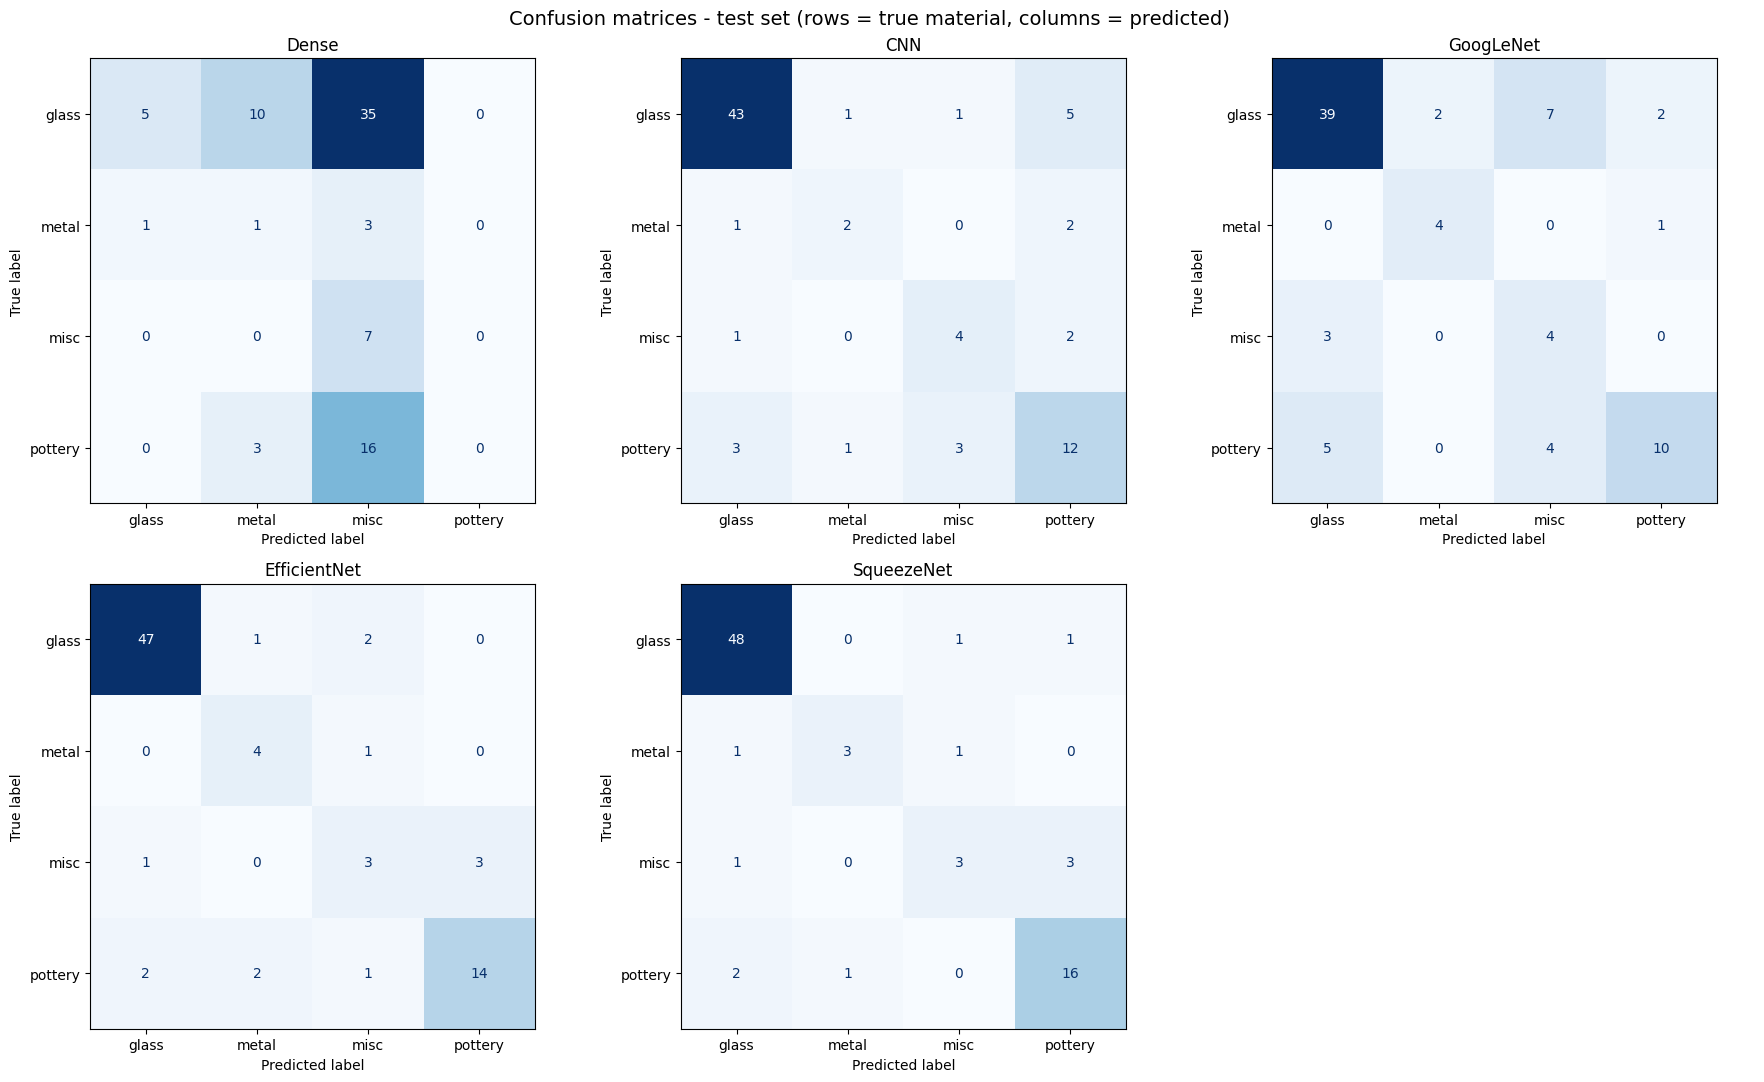

Saved to 05_results/classification_confusion_matrices.png


In [ ]:
# Confusion matrices for all five models
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, (model_name, model) in zip(axes, all_models.items()):
    true_labels, predicted_labels = get_predictions(model)

    matrix = confusion_matrix(true_labels, predicted_labels)
    display = ConfusionMatrixDisplay(matrix, display_labels=class_names)
    display.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(model_name)

axes[-1].axis('off')

plt.suptitle('Confusion matrices - test set (rows = true material, columns = predicted)',
             fontsize=14)
plt.tight_layout()
plt.savefig(RESULTS / 'classification_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved to 05_results/classification_confusion_matrices.png")

In [ ]:
CLS_WEIGHTS = ROOT / '02_classification' / 'weights'
CLS_WEIGHTS.mkdir(parents=True, exist_ok=True)

torch.save(squeezenet_model.state_dict(),   CLS_WEIGHTS / 'squeezenet_best.pt')
torch.save(efficientnet_model.state_dict(), CLS_WEIGHTS / 'efficientnet_best.pt')
torch.save(googlenet_model.state_dict(),    CLS_WEIGHTS / 'googlenet_best.pt')
torch.save(cnn_model.state_dict(),          CLS_WEIGHTS / 'cnn_best.pt')
torch.save(dense_model.state_dict(),        CLS_WEIGHTS / 'dense_best.pt')

print("Saved classifier weights to 02_classification/weights/")

Saved classifier weights to 02_classification/weights/
